# 单股票五模型验证结果

指定 `RUN_NAME`，选择 **EE6008** 内核并从头运行。

## 1. 实验目录校验与资源记录

`RUN_NAME` 只填写 `artifacts/` 下的目录名。默认要求五模型齐全，查看部分模型时将 `REQUIRE_ALL_MODELS` 设为 `False`。

校验实验状态、原始数据指纹、日期与标签、预处理参数及保存指标。原始 CSV 需与实验版本一致；重建数据集仅用于核验。

下表记录设备、耗时、最佳轮次和实际训练轮数。轮次统一从 **1** 开始；耗时受设备等因素影响，仅作资源记录。

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# 从当前位置向上定位项目根目录。
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "main.py").is_file() and (p / "src/data.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project or notebooks directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import importlib
import src.data as data_module
from src.evaluate import evaluate

MODELS = ("xgboost", "lightgbm", "patchtst", "lstm", "gru")
BASELINES = ("zero_return", "historical_mean", "last_return")
LABELS = {"xgboost": "XGBoost", "lightgbm": "LightGBM", "patchtst": "PatchTST",
          "lstm": "LSTM", "gru": "GRU", "zero_return": "Zero return",
          "historical_mean": "Historical mean", "last_return": "Last return"}
# 必填：只写 artifacts/ 下已有的实验目录名，并加英文引号。
RUN_NAME = 'aapl_compare_all_02'

# True：要求包含五个模型；False：允许查看指定目录中的部分模型。
REQUIRE_ALL_MODELS = True

# 仅控制右侧曲线显示的天数，不改变模型输入窗口或完整验证指标
RECENT_DAYS = 80


plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Python:", sys.executable)

Python: f:\Enviornment\miniforge3\envs\EE6008\python.exe


In [2]:
def read_json(path):
    return json.loads(path.read_text(encoding="utf-8-sig"))


# 必须显式指定 artifacts/ 下的一个目录名；不扫描、不自动选择、不回退。
if not isinstance(RUN_NAME, str) or not RUN_NAME.strip():
    raise ValueError('请设置 RUN_NAME = "实际实验目录名"；不能使用 None 或空字符串')
if Path(RUN_NAME).name != RUN_NAME or RUN_NAME in (".", ".."):
    raise ValueError("RUN_NAME 只填写 artifacts/ 下的目录名，不填写路径")
run_dir = ROOT / "artifacts" / RUN_NAME
if not run_dir.is_dir():
    raise FileNotFoundError(f"实验目录不存在：{run_dir}")
required_files = ("manifest.json", "config.json", "metrics.json", "training.json",
                  "preprocessing.json", "direction_reference.json", "predictions.csv")
missing_files = [name for name in required_files if not (run_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"实验 {RUN_NAME} 缺少文件：{', '.join(missing_files)}")

# 股票名称和数据位置以实验快照为准，不依赖 Notebook 名称或当前训练配置。
manifest = read_json(run_dir / "manifest.json")
config = read_json(run_dir / "config.json")
ticker = config.get("ticker")
if not isinstance(ticker, str) or not ticker.strip():
    raise ValueError("实验 config.json 必须包含非空的 ticker 股票代码")
if not isinstance(config.get("data_path"), str) or not config["data_path"].strip():
    raise ValueError("实验 config.json 必须包含非空的 data_path 数据路径")
if (manifest.get("status") != "complete" or manifest.get("evaluation_split") != "validation"
        or manifest.get("test_evaluated", False) or manifest.get("holdout_evaluated", False)):
    raise ValueError("请选择已完成、且未评价测试期或保留期的验证实验")
saved_metrics = read_json(run_dir / "metrics.json")
missing_models = [name for name in MODELS if name not in saved_metrics]
if REQUIRE_ALL_MODELS and missing_models:
    raise ValueError(f"本次实验缺少模型：{', '.join(missing_models)}；查看部分模型请设置 REQUIRE_ALL_MODELS = False")
training = read_json(run_dir / "training.json")
preprocessing = read_json(run_dir / "preprocessing.json")
reference = read_json(run_dir / "direction_reference.json")

# 核对当前原始 CSV 是否与训练时相同；不是重新下载数据。
current_hash = hashlib.sha256((ROOT / config["data_path"]).read_bytes()).hexdigest()
if current_hash != manifest["data_sha256"]:
    raise ValueError("Raw data differs from this experiment; restore the matching data version")
# 重建数据集只用于探索和一致性核对，不会调用任何模型训练函数。
# Refresh local code even when this kernel was started before a code update.
# Reject a module from another checkout instead of silently using its dataset rules.
if Path(data_module.__file__).resolve() != (ROOT / "src/data.py").resolve():
    raise RuntimeError("src.data was imported from another project. Restart the kernel and Run All.")
importlib.invalidate_caches()
data_module = importlib.reload(data_module)
dataset = data_module.load_dataset(config, ROOT)
# Read the feature selection from this run; older snapshots default to all eight.
features = dataset.features
if preprocessing["features"] != features or preprocessing["window"] != config["window"]:
    raise ValueError("Feature order or historical window does not match")
np.testing.assert_allclose(dataset.feature_mean, preprocessing["feature_mean"], rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(dataset.feature_scale, preprocessing["feature_scale"], rtol=1e-10, atol=1e-12)
np.testing.assert_allclose([dataset.target_mean, dataset.target_scale],
                          [preprocessing["target_mean"], preprocessing["target_scale"]], rtol=1e-10)

# 真正用于对比的模型预测来自已保存的 CSV，不是在 Notebook 里重新预测。
predictions = pd.read_csv(run_dir / "predictions.csv",
                          parse_dates=["window_start", "signal_date", "target_date"], float_precision="round_trip")
if predictions.target_date.duplicated().any() or not predictions.target_date.is_monotonic_increasing:
    raise ValueError("Prediction target dates must be unique and chronological")
for column in ("window_start", "signal_date", "target_date"):
    np.testing.assert_array_equal(predictions[column].to_numpy(), dataset.validation.dates[column].to_numpy())
np.testing.assert_allclose(predictions.actual_return, dataset.validation.y, rtol=0, atol=1e-12)
np.testing.assert_array_equal(predictions.actual_direction, (dataset.validation.y > 0).astype(int))
learned = [name for name in MODELS if name in saved_metrics]
names = [*BASELINES, *learned]
# 用完整验证集的真实值和已保存预测重算指标，再与 metrics.json 核对。
# 这是评价计算，不是重新训练；RECENT_DAYS 不会参与此处计算。
metrics = {}
for name in names:
    if name not in predictions or name not in saved_metrics:
        raise ValueError(f"Missing prediction or metrics for {name}")
    metrics[name] = evaluate(predictions.actual_return.to_numpy(), predictions[name].to_numpy())
    for key, value in metrics[name].items():
        saved = saved_metrics[name][key]
        if value is None or saved is None:
            if value != saved:
                raise ValueError(f"{name}: inconsistent metric {key}")
        else:
            np.testing.assert_allclose(value, saved, rtol=1e-8, atol=1e-12,
                                       err_msg=f"{name}: {key} disagrees with predictions")
# 同时核对训练期固定多数方向在验证集上的准确率。
if not isinstance(reference.get("train_majority_up"), bool):
    raise ValueError("Missing training-majority direction")
np.testing.assert_allclose(reference["validation_accuracy"],
    np.mean((predictions.actual_return > 0) == reference["train_majority_up"]), rtol=0, atol=1e-12)
print(f"校验通过 | {ticker} | {run_dir.name} | seed={config['seed']}")
print(f"训练：{dataset.audit['train_target_first']} 至 {dataset.audit['train_target_last']}，{len(dataset.train.y)} 个样本")
print(f"验证：{predictions.target_date.min().date()} 至 {predictions.target_date.max().date()}，{len(predictions)} 个样本")
print(f"输入：最近 {config['window']} 个交易日 × {len(features)} 个特征 | 数据：{config['data_path']}")

# 资源记录来自 training.json，不加载模型或重新训练。
records = []
for name in learned:
    info = training[name]
    if name == "xgboost":
        selected = info["best_iteration"] + 1
        steps = len(info["history"]["validation_0"]["rmse"])
    elif name == "lightgbm":
        selected = info["best_iteration"]
        steps = len(info["history"]["validation"]["rmse"])
    else:
        selected = info["best_epoch"]
        steps = len(info["history"])
    records.append({"Model": LABELS[name], "Device": info.get("device"),
                    "Seconds": info["seconds"], "Selected step": selected,
                    "Steps evaluated": steps})
if records:
    display(pd.DataFrame(records).set_index("Model").style.format({"Seconds": "{:.3f}"}))
else:
    print("本次实验只有基线，无模型训练资源记录。")

校验通过 | AAPL | aapl_compare_all_02 | seed=42
训练：2010-04-01 至 2021-12-31，2960 个样本
验证：2022-01-03 至 2023-12-29，501 个样本
输入：最近 60 个交易日 × 8 个特征 | 数据：data/AAPL_Apple_stock_data.csv


,Device,Seconds,Selected step,Steps evaluated
Model,,,,
XGBoost,cpu,0.619,57,137
LightGBM,cpu,0.296,51,131
PatchTST,cuda,3.272,4,10
LSTM,cuda,2.896,6,14
GRU,cuda,1.995,2,10


## 2. 模型结果表格

五模型与三个简单基线合并为一个表，按**方向准确率降序**排列。

- **Direction accuracy / Up F1**：方向准确率与上涨类 F1；结合真实、预测上涨比例及多数方向基线阅读。
- **MAE / RMSE**：越低越好，单位为收益百分点（pp），原始文件仍保存小数收益。
- **R2 / R2 vs zero**：分别参照验证期均值和零收益，越高越好。

所有指标使用完整验证期，不受 `RECENT_DAYS` 影响。

In [3]:
# 使用完整验证期指标；模型与三个基线合并展示，按方向准确率降序排列。
# 同分时保留原始顺序，不用其他指标打破平局。
summary = pd.DataFrame(metrics).T
columns = ["n", "direction_accuracy", "up_f1", "actual_up_rate", "predicted_up_rate",
           "mae", "rmse", "r2", "r2_vs_zero"]
results = summary[columns].astype(float).sort_values("direction_accuracy", ascending=False, kind="stable")
results["n"] = results["n"].astype(int)
results[["mae", "rmse"]] *= 100  # 小数收益转换成收益百分点，仅用于展示。
results = results.rename(index=LABELS, columns={"n": "N", "direction_accuracy": "Direction accuracy",
    "up_f1": "Up F1", "actual_up_rate": "Actual up rate", "predicted_up_rate": "Predicted up rate",
    "mae": "MAE (pp)", "rmse": "RMSE (pp)", "r2": "R2", "r2_vs_zero": "R2 vs zero"})
results.index.name = "Model"
display(results.style.format({"N": "{:d}", "Direction accuracy": "{:.2%}",
    "Up F1": "{:.4f}", "Actual up rate": "{:.2%}", "Predicted up rate": "{:.2%}",
    "MAE (pp)": "{:.4f}", "RMSE (pp)": "{:.4f}", "R2": "{:.4f}", "R2 vs zero": "{:.4f}"}, na_rep="N/A"))
print(f"训练期固定多数方向的验证准确率：{reference['validation_accuracy']:.2%}")

,N,Direction accuracy,Up F1,Actual up rate,Predicted up rate,MAE (pp),RMSE (pp),R2,R2 vs zero
Model,,,,,,,,,
PatchTST,501,54.49%,0.6250,51.30%,70.06%,1.3996,1.8712,-0.0443,-0.0439
LightGBM,501,51.50%,0.6389,51.30%,83.03%,1.3608,1.8042,0.0291,0.0294
Historical mean,501,51.30%,0.6781,51.30%,100.00%,1.3612,1.8331,-0.0022,-0.0019
GRU,501,51.10%,0.6349,51.30%,82.63%,1.3615,1.8323,-0.0013,-0.0010
XGBoost,501,50.70%,0.6555,51.30%,91.82%,1.3574,1.8198,0.0123,0.0126
Last return,501,50.50%,0.5175,51.30%,51.30%,1.9277,2.5931,-1.0054,-1.0048
LSTM,501,49.30%,0.5621,51.30%,64.47%,1.3700,1.8295,0.0017,0.0020
Zero return,501,48.70%,0.0000,51.30%,0.00%,1.3611,1.8314,-0.0003,0.0000


训练期固定多数方向的验证准确率：51.30%


## 3. 模型结果曲线图

每行一个模型：左侧展示完整验证期，右侧展示最近 `RECENT_DAYS` 个目标日；灰线为真实收益，彩线为预测收益。各图使用相同纵轴范围。

`RECENT_DAYS` 只控制局部展示长度，不是模型的历史输入窗口。

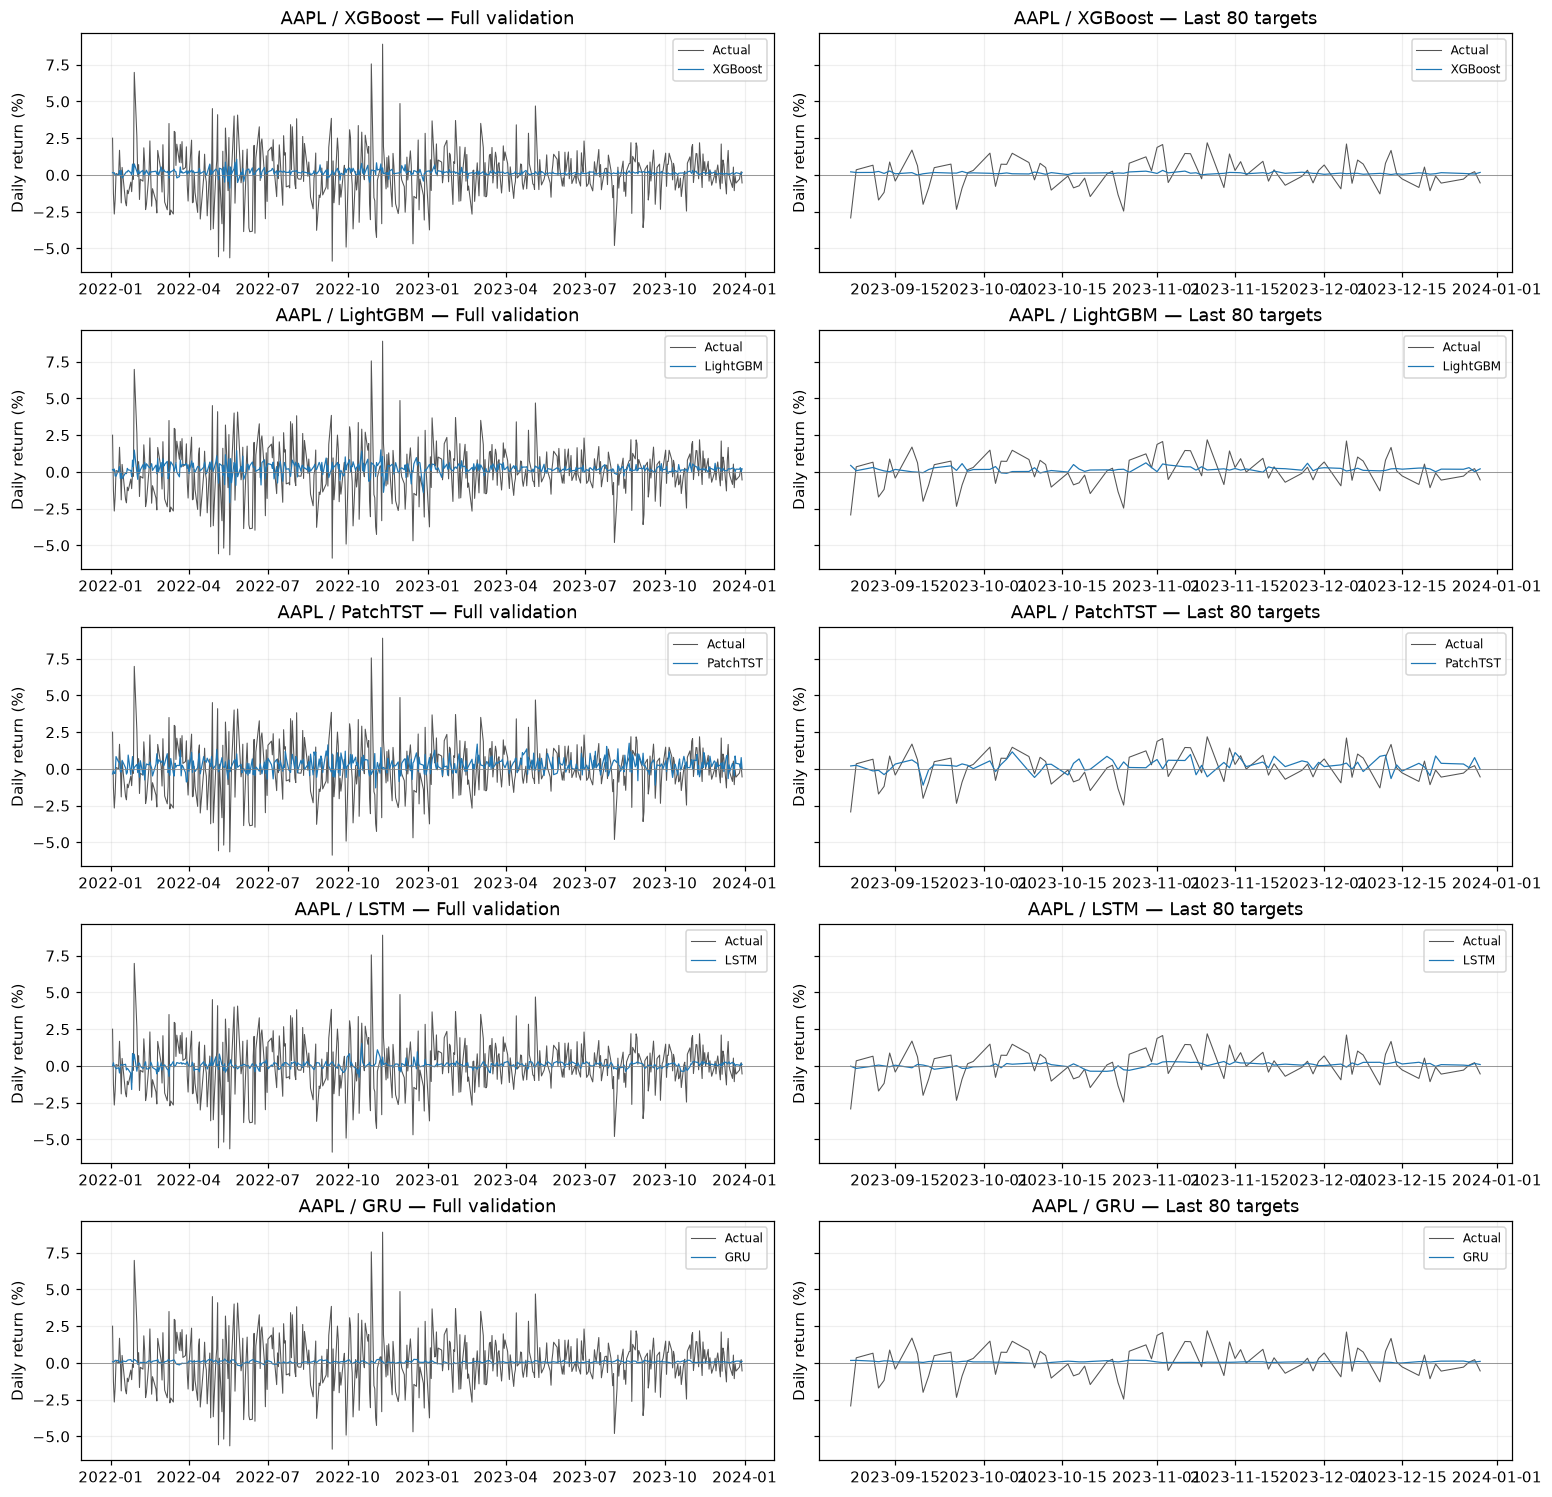

In [4]:
if not isinstance(RECENT_DAYS, int) or isinstance(RECENT_DAYS, bool) or RECENT_DAYS < 1:
    raise ValueError("RECENT_DAYS 必须为正整数")
if learned:
    fig, axes = plt.subplots(len(learned), 2, figsize=(14, 2.7 * len(learned)),
                             squeeze=False, sharey=True, layout="constrained")
    for row, name in enumerate(learned):
        for ax, frame, title in zip(axes[row], (predictions, predictions.tail(RECENT_DAYS)),
                                   ("Full validation", f"Last {RECENT_DAYS} targets")):
            ax.plot(frame.target_date, frame.actual_return * 100, label="Actual", linewidth=0.7, color="#555555")
            ax.plot(frame.target_date, frame[name] * 100, label=LABELS[name], linewidth=0.8)
            ax.axhline(0, color="grey", linewidth=0.5)
            ax.set(title=f"{ticker} / {LABELS[name]} — {title}", ylabel="Daily return (%)")
            ax.legend(fontsize=8); ax.grid(alpha=0.2)
    plt.show()
    plt.close(fig)
else:
    print("本次实验只有基线，无模型预测曲线。")